### Step 1 — Confirm Jupyter is using this folder

In [2]:
from pathlib import Path

PROJECT_DIR = Path(
    "/Users/pranalikadam/Documents/AI:ML Codes/ML/PhishingDataset/phishing"
)

print("Folder exists:", PROJECT_DIR.exists())
print("Files in folder:")
for file in PROJECT_DIR.iterdir():
    print(file.name)

Folder exists: True
Files in folder:
.DS_Store
.old.arff
Training Dataset.arff
Phishing_Datset_Exploration.ipynb
.ipynb_checkpoints
Phishing Websites Features.docx


### Step 2 — Load the ARFF file

In [3]:
%pip install liac-arff

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for liac-arff: filename=liac_arff-2.5.0-py3-none-any.whl size=11772 sha256=750684bb2492c990b62b6a80076ce35a9090eb9ce79c668b7bfff89d516a442f
  Stored in directory: /Users/pranalikadam/Library/Caches/pip/wheels/0f/0d/22/0b7a6ecc989eedde58f06a84063f88bcc93e5346cb4dccb045
Successfully built liac-arff

[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [4]:
import arff
import pandas as pd
import numpy as np

file_path = PROJECT_DIR / "Training Dataset.arff"

with open(file_path, "r") as file:
    arff_data = arff.load(file)

df = pd.DataFrame(
    arff_data["data"],
    columns=[attribute[0] for attribute in arff_data["attributes"]]
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (11055, 31)


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,Result
0,-1,1,1,1,-1,-1,-1,-1,-1,1,...,1,1,-1,-1,-1,-1,1,1,-1,-1
1,1,1,1,1,1,-1,0,1,-1,1,...,1,1,-1,-1,0,-1,1,1,1,-1
2,1,0,1,1,1,-1,-1,-1,-1,1,...,1,1,1,-1,1,-1,1,0,-1,-1
3,1,0,1,1,1,-1,-1,-1,1,1,...,1,1,-1,-1,1,-1,1,-1,1,-1
4,1,0,-1,1,1,-1,1,1,-1,1,...,-1,1,-1,-1,0,-1,1,1,1,1


#### Step 2 — Dataset inspection

In [5]:
# Display all column names
print("Columns:")
print(df.columns.tolist())

# Check data types
print("\nData types:")
print(df.dtypes.value_counts())

# Check missing values
print("\nTotal missing values:", df.isnull().sum().sum())

# Check exact duplicate rows
print("Exact duplicate rows:", df.duplicated().sum())

# Check target distribution
print("\nTarget distribution:")
print(df["Result"].value_counts().sort_index())

print("\nTarget percentages:")
print((df["Result"].value_counts(normalize=True).sort_index() * 100).round(2))

Columns:
['having_IP_Address', 'URL_Length', 'Shortining_Service', 'having_At_Symbol', 'double_slash_redirecting', 'Prefix_Suffix', 'having_Sub_Domain', 'SSLfinal_State', 'Domain_registeration_length', 'Favicon', 'port', 'HTTPS_token', 'Request_URL', 'URL_of_Anchor', 'Links_in_tags', 'SFH', 'Submitting_to_email', 'Abnormal_URL', 'Redirect', 'on_mouseover', 'RightClick', 'popUpWidnow', 'Iframe', 'age_of_domain', 'DNSRecord', 'web_traffic', 'Page_Rank', 'Google_Index', 'Links_pointing_to_page', 'Statistical_report', 'Result']

Data types:
str    31
Name: count, dtype: int64

Total missing values: 0
Exact duplicate rows: 5206

Target distribution:
Result
-1    4898
1     6157
Name: count, dtype: int64

Target percentages:
Result
-1    44.31
1     55.69
Name: proportion, dtype: float64


#### Step 3 — Understand the target labels

In [9]:
print("Target labels:", sorted(df["Result"].unique()))

print("\nTarget meaning:")
print("-1 = Phishing website")
print(" 1 = Legitimate website")

Target labels: [np.int64(-1), np.int64(1)]

Target meaning:
-1 = Phishing website
 1 = Legitimate website


#### Step 4 - Convert all columns to numeric

In [7]:
# Convert all columns from strings to numeric values
df = df.apply(pd.to_numeric, errors="raise")

print("Data types after conversion:")
print(df.dtypes.value_counts())

print("\nTarget labels after conversion:")
print(df["Result"].value_counts().sort_index())

Data types after conversion:
int64    31
Name: count, dtype: int64

Target labels after conversion:
Result
-1    4898
 1    6157
Name: count, dtype: int64


#### Step 5 — Investigate duplicates

In [10]:
# Count exact duplicate rows
exact_duplicates = df.duplicated().sum()

# Separate features and target
X_all = df.drop("Result", axis=1)
y_all = df["Result"]

# Count duplicate feature rows, ignoring target
duplicate_features = X_all.duplicated().sum()

# Find feature combinations associated with conflicting labels
label_counts_per_feature = (
    df.groupby(list(X_all.columns))["Result"]
      .nunique()
)

conflicting_feature_groups = (label_counts_per_feature > 1).sum()

print("Exact duplicate rows:", exact_duplicates)
print("Repeated feature rows:", duplicate_features)
print("Feature groups with conflicting labels:", conflicting_feature_groups)

Exact duplicate rows: 5206
Repeated feature rows: 5270
Feature groups with conflicting labels: 64


#### Step 6- inspect the conflicting groups

In [12]:
X_all = df.drop("Result", axis=1)

label_counts = (
    df.groupby(list(X_all.columns))["Result"]
      .value_counts()
      .unstack(fill_value=0)
)

conflicting_groups = label_counts[
    (label_counts.get(-1, 0) > 0) &
    (label_counts.get(1, 0) > 0)
]

print("Number of conflicting feature groups:", len(conflicting_groups))
print("\nFirst 10 conflicting groups:")
print(conflicting_groups.head(10))

print("\nTotal rows belonging to conflicting groups:")
print(conflicting_groups.sum(axis=1).sum())

Number of conflicting feature groups: 64

First 10 conflicting groups:
Result                                                                                                                                                                                                                                                                                                                                                                                                                               -1  \
having_IP_Address URL_Length Shortining_Service having_At_Symbol double_slash_redirecting Prefix_Suffix having_Sub_Domain SSLfinal_State Domain_registeration_length Favicon port HTTPS_token Request_URL URL_of_Anchor Links_in_tags SFH Submitting_to_email Abnormal_URL Redirect on_mouseover RightClick popUpWidnow Iframe age_of_domain DNSRecord web_traffic Page_Rank Google_Index Links_pointing_to_page Statistical_report       
-1                -1         1                  1                1         

#### Step 8- prepare features and target

In [13]:
from sklearn.model_selection import GroupShuffleSplit

# Remove exact duplicate rows only (same features and same target)
df_clean = df.drop_duplicates().copy()

# Features
X = df_clean.drop(columns=["Result"])

# Target: 1 = phishing, 0 = legitimate
y = (df_clean["Result"] == -1).astype(int)
y.name = "is_phishing"

# Group identical feature rows together
groups = X.astype(str).agg("|".join, axis=1)

print("Original rows:", len(df))
print("Rows after exact duplicate removal:", len(df_clean))
print("Feature count:", X.shape[1])
print("\nTarget distribution:")
print(y.value_counts().sort_index().rename(index={0: "Legitimate", 1: "Phishing"}))
print("\nUnique feature groups:", groups.nunique())

Original rows: 11055
Rows after exact duplicate removal: 5849
Feature count: 30

Target distribution:
is_phishing
Legitimate    2830
Phishing      3019
Name: count, dtype: int64

Unique feature groups: 5785


#### Step 9 — group-aware train/test split

In [14]:
from sklearn.model_selection import GroupShuffleSplit

# Split so identical feature combinations stay in one partition
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx]
groups_test = groups.iloc[test_idx]

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining class distribution:")
print(y_train.value_counts().sort_index().rename(
    index={0: "Legitimate", 1: "Phishing"}
))

print("\nTesting class distribution:")
print(y_test.value_counts().sort_index().rename(
    index={0: "Legitimate", 1: "Phishing"}
))

print("\nFeature groups shared between train and test:",
      len(set(groups_train) & set(groups_test)))

Training rows: 4679
Testing rows: 1170

Training class distribution:
is_phishing
Legitimate    2234
Phishing      2445
Name: count, dtype: int64

Testing class distribution:
is_phishing
Legitimate    596
Phishing      574
Name: count, dtype: int64

Feature groups shared between train and test: 0


In [15]:
import time
import pandas as pd

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

models = {
    "Logistic Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LogisticRegression(max_iter=2000, random_state=42))
    ]),

    "Decision Tree": DecisionTreeClassifier(random_state=42),

    "KNN": Pipeline([
        ("scaler", StandardScaler()),
        ("model", KNeighborsClassifier(n_neighbors=5))
    ]),

    "Gaussian Naive Bayes": GaussianNB(),

    "SVM": Pipeline([
        ("scaler", StandardScaler()),
        ("model", SVC(kernel="rbf", random_state=42))
    ])
}

training_times = {}

for name, model in models.items():
    start = time.time()
    model.fit(X_train, y_train)
    training_times[name] = time.time() - start
    print(f"{name} trained in {training_times[name]:.2f} seconds")

print("\nAll five models trained successfully.")

Logistic Regression trained in 0.02 seconds
Decision Tree trained in 0.01 seconds
KNN trained in 0.00 seconds
Gaussian Naive Bayes trained in 0.00 seconds
SVM trained in 0.12 seconds

All five models trained successfully.


In [16]:
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

results = []
predictions = {}
auc_scores = {}

for name, model in models.items():
    # Predict phishing / legitimate labels
    y_pred = model.predict(X_test)
    predictions[name] = y_pred

    # Get model scores for AUC
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    auc = roc_auc_score(y_test, y_score)
    auc_scores[name] = y_score

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "AUC": auc,
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1": f1_score(y_test, y_pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, y_pred)
    })

results_df = pd.DataFrame(results).set_index("Model")

print("Test-set model comparison:")
display(results_df.round(4))

Test-set model comparison:


,Accuracy,AUC,Precision,Recall,F1,MCC
Model,,,,,,
Logistic Regression,0.9120,0.9722,0.9168,0.9024,0.9096,0.8239
Decision Tree,0.9291,0.9398,0.9392,0.9146,0.9267,0.8583
KNN,0.9265,0.9817,0.9136,0.9390,0.9261,0.8533
Gaussian Naive Bayes,0.6256,0.9653,0.5673,0.9983,0.7235,0.3856
SVM,0.9299,0.9831,0.9473,0.9077,0.9270,0.8604


### Confusion Matrix and Classification Report


Logistic Regression

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.91      0.92      0.91       596
    Phishing       0.92      0.90      0.91       574

    accuracy                           0.91      1170
   macro avg       0.91      0.91      0.91      1170
weighted avg       0.91      0.91      0.91      1170



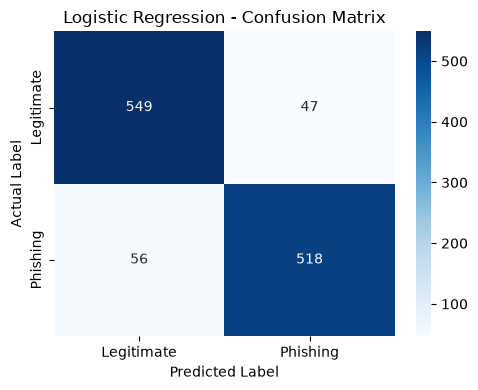


Decision Tree

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.92      0.94      0.93       596
    Phishing       0.94      0.91      0.93       574

    accuracy                           0.93      1170
   macro avg       0.93      0.93      0.93      1170
weighted avg       0.93      0.93      0.93      1170



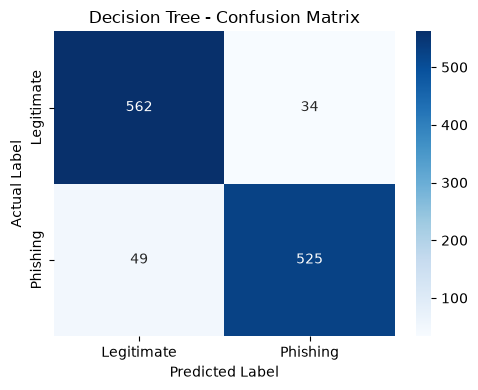


KNN

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.94      0.91      0.93       596
    Phishing       0.91      0.94      0.93       574

    accuracy                           0.93      1170
   macro avg       0.93      0.93      0.93      1170
weighted avg       0.93      0.93      0.93      1170



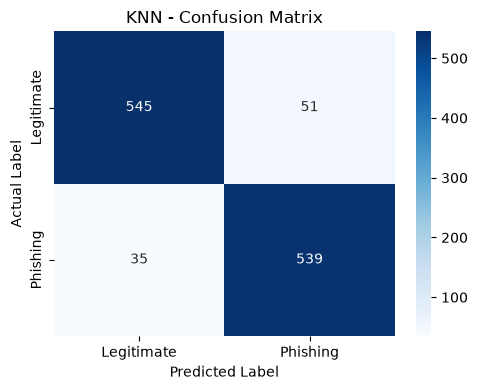


Gaussian Naive Bayes

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.99      0.27      0.42       596
    Phishing       0.57      1.00      0.72       574

    accuracy                           0.63      1170
   macro avg       0.78      0.63      0.57      1170
weighted avg       0.78      0.63      0.57      1170



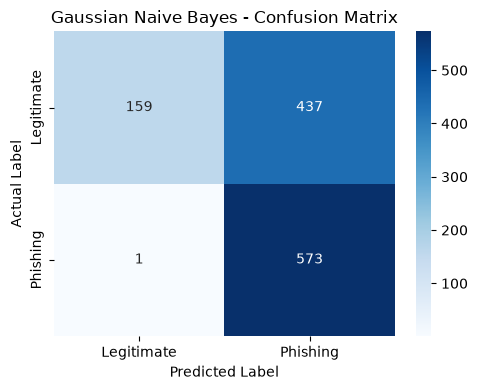


SVM

Classification Report:
              precision    recall  f1-score   support

  Legitimate       0.91      0.95      0.93       596
    Phishing       0.95      0.91      0.93       574

    accuracy                           0.93      1170
   macro avg       0.93      0.93      0.93      1170
weighted avg       0.93      0.93      0.93      1170



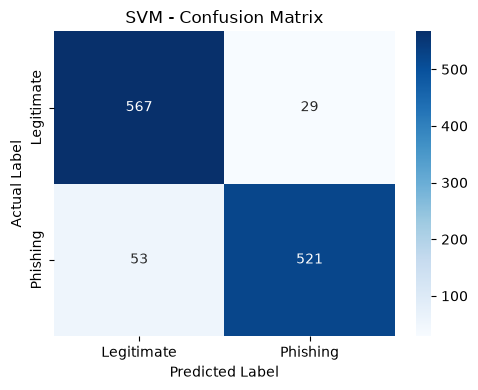

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report
)

for name, y_pred in predictions.items():

    cm = confusion_matrix(y_test, y_pred)

    print("\n" + "=" * 55)
    print(name)
    print("=" * 55)

    print("\nClassification Report:")
    print(classification_report(
        y_test,
        y_pred,
        target_names=["Legitimate", "Phishing"],
        zero_division=0
    ))

    plt.figure(figsize=(5, 4))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Legitimate", "Phishing"],
        yticklabels=["Legitimate", "Phishing"]
    )

    plt.title(f"{name} - Confusion Matrix")
    plt.xlabel("Predicted Label")
    plt.ylabel("Actual Label")
    plt.tight_layout()
    plt.show()

### ROC curve comparison

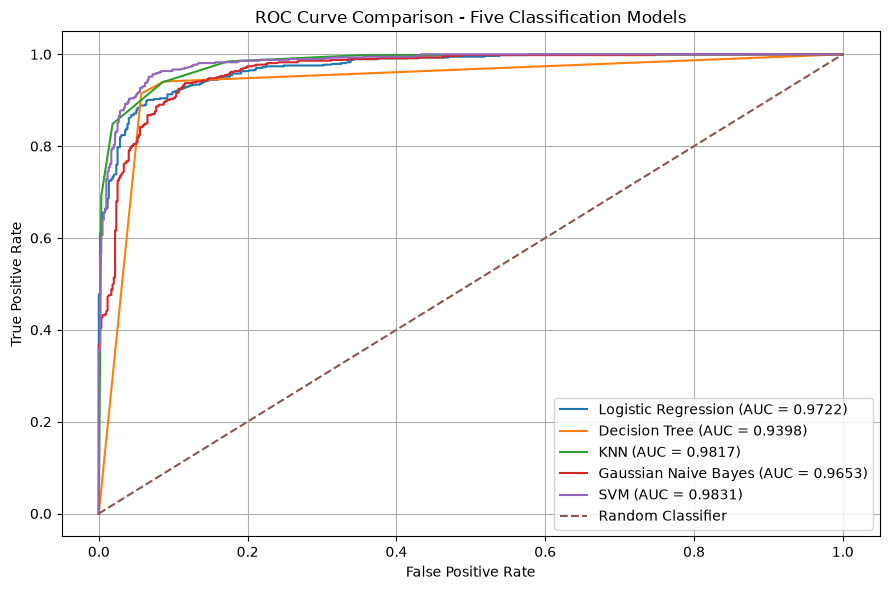

In [18]:
import matplotlib.pyplot as plt

from sklearn.metrics import roc_curve, roc_auc_score

plt.figure(figsize=(9, 6))

for name, model in models.items():

    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    fpr, tpr, thresholds = roc_curve(y_test, y_score)
    auc = roc_auc_score(y_test, y_score)

    plt.plot(
        fpr,
        tpr,
        label=f"{name} (AUC = {auc:.4f})"
    )

plt.plot([0, 1], [0, 1], linestyle="--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Five Classification Models")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [19]:
for name, score in auc_scores.items():
    print(f"{name}: AUC = {roc_auc_score(y_test, score):.4f}")

Logistic Regression: AUC = 0.9722
Decision Tree: AUC = 0.9398
KNN: AUC = 0.9817
Gaussian Naive Bayes: AUC = 0.9653
SVM: AUC = 0.9831


### Save all five trained models

In [20]:
import joblib
import json
from pathlib import Path

# Create model folder
MODEL_DIR = PROJECT_DIR / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save all five trained models
for name, model in models.items():
    filename = name.lower().replace(" ", "_") + ".joblib"

    joblib.dump(
        model,
        MODEL_DIR / filename
    )

    print(f"Saved: {filename}")

# Save feature information
metadata = {
    "dataset": "UCI Phishing Websites",
    "target_column": "is_phishing",
    "target_mapping": {
        "0": "Legitimate",
        "1": "Phishing"
    },
    "features": X.columns.tolist(),
    "models": list(models.keys()),
    "random_state": 42
}

with open(MODEL_DIR / "metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("\nAll models and metadata saved successfully!")
print("Model folder:", MODEL_DIR)

Saved: logistic_regression.joblib
Saved: decision_tree.joblib
Saved: knn.joblib
Saved: gaussian_naive_bayes.joblib
Saved: svm.joblib

All models and metadata saved successfully!
Model folder: /Users/pranalikadam/Documents/AI:ML Codes/ML/PhishingDataset/phishing/models


### Create test_data.csv

In [21]:
# Combine test features and actual target labels
test_data = X_test.copy()

test_data["is_phishing"] = y_test.values

# Save CSV in project folder
TEST_FILE = PROJECT_DIR / "test_data.csv"

test_data.to_csv(TEST_FILE, index=False)

print("Test CSV created successfully!")
print("File location:", TEST_FILE)
print("Dataset shape:", test_data.shape)

print("\nFirst 5 rows:")
display(test_data.head())

print("\nTarget distribution:")
print(
    test_data["is_phishing"]
    .value_counts()
    .rename(index={0: "Legitimate", 1: "Phishing"})
)

Test CSV created successfully!
File location: /Users/pranalikadam/Documents/AI:ML Codes/ML/PhishingDataset/phishing/test_data.csv
Dataset shape: (1170, 31)

First 5 rows:


,having_IP_Address,URL_Length,Shortining_Service,having_At_Symbol,double_slash_redirecting,Prefix_Suffix,having_Sub_Domain,SSLfinal_State,Domain_registeration_length,Favicon,...,popUpWidnow,Iframe,age_of_domain,DNSRecord,web_traffic,Page_Rank,Google_Index,Links_pointing_to_page,Statistical_report,is_phishing
10,1,1,1,1,1,-1,0,1,1,1,...,1,1,-1,1,1,1,1,-1,-1,0
18,1,1,1,1,1,-1,-1,1,1,1,...,1,1,1,-1,-1,1,1,-1,-1,0
24,1,-1,-1,-1,1,-1,1,1,-1,1,...,1,1,1,1,-1,-1,1,0,1,0
27,1,-1,-1,1,1,1,-1,1,1,1,...,1,1,1,-1,0,-1,1,0,-1,0
33,1,0,1,1,1,-1,-1,1,-1,1,...,1,1,1,1,1,-1,1,0,-1,0



Target distribution:
is_phishing
Legitimate    596
Phishing      574
Name: count, dtype: int64


### Verify saved models

In [22]:
import joblib
from sklearn.metrics import accuracy_score

for name in models.keys():

    filename = name.lower().replace(" ", "_") + ".joblib"

    # Load saved model
    loaded_model = joblib.load(MODEL_DIR / filename)

    # Predict using loaded model
    predictions_loaded = loaded_model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions_loaded)

    print(f"{name}: {accuracy:.4f}")

print("\nAll saved models loaded and verified successfully!")

Logistic Regression: 0.9120
Decision Tree: 0.9291
KNN: 0.9265
Gaussian Naive Bayes: 0.6256
SVM: 0.9299

All saved models loaded and verified successfully!


In [23]:
%pip install streamlit pandas numpy scikit-learn matplotlib seaborn joblib


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.
